# Macierz korelacji – dolny trójkąt

Notebook pokazuje, jak przygotować czytelną macierz korelacji dla zmiennych numerycznych.

**Cel:** pozostawić tylko jeden trójkąt macierzy, aby nie prezentować dwukrotnie tych samych zależności.

Dane są syntetyczne i służą wyłącznie demonstracji.

## 1. Dane syntetyczne

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

rng = np.random.default_rng(42)
n = 100

wiek = rng.integers(22, 61, n)
staz = np.clip(wiek - 22 + rng.normal(0, 5, n), 0, None)
wynagrodzenie = 4000 + staz * 350 + rng.normal(0, 1800, n)
liczba_produktow = np.clip(1 + staz / 8 + rng.normal(0, 1, n), 0, 8)
satysfakcja = np.clip(7 - staz * 0.025 + rng.normal(0, 1.2, n), 1, 10)

df = pd.DataFrame(
    {
        "Wiek": wiek,
        "Staz": staz.round(1),
        "Wynagrodzenie": wynagrodzenie.round(0),
        "Liczba_produktow": liczba_produktow.round(0),
        "Satysfakcja": satysfakcja.round(1),
    }
)

df.head()

,Wiek,Staz,Wynagrodzenie,Liczba_produktow,Satysfakcja
0,25,6.4,8157.0,5.0,4.9
1,52,30.3,14901.0,4.0,8.0
2,47,26.4,12970.0,4.0,6.8
3,39,20.2,9191.0,4.0,7.5
4,38,8.7,4036.0,4.0,6.1


## 2. Obliczenie korelacji

Wybierz metodę korelacji. Pearson mierzy zależność liniową, Spearman i Kendall opierają się na rangach.

In [2]:
metoda = "pearson"  # "pearson", "spearman" lub "kendall"

corr = df.select_dtypes(include="number").corr(method=metoda)

# Usunięcie pierwszego wiersza i ostatniej kolumny pozwala pokazać jeden trójkąt bez pustego brzegu macierzy.
corr = corr.iloc[1:, :-1]

# Ukryj górny trójkąt, ale pozostaw przekątną przyciętej macierzy.
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)

## 3. Wizualizacja

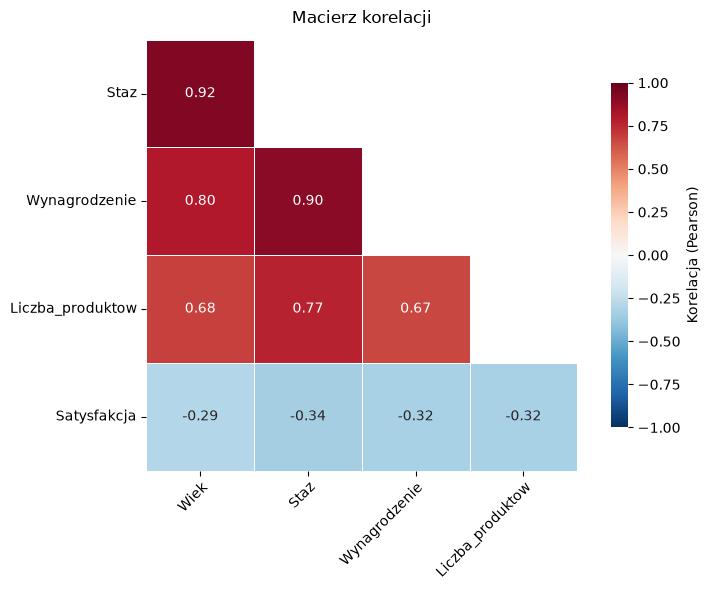

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8, "label": f"Korelacja ({metoda.capitalize()})"},
    ax=ax,
)

ax.set_title("Macierz korelacji", pad=12)
ax.tick_params(labelsize=10)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()

## 4. Interpretacja

- **Wartość bliska +1** – silna dodatnia zależność.
- **Wartość bliska -1** – silna ujemna zależność.
- **Wartość bliska 0** – brak wyraźnej zależności monotonicznej (dla Pearsona: liniowej).

Korelacja nie oznacza związku przyczynowo-skutkowego. Wynik należy interpretować w kontekście danych i rodzaju zmiennych.

**Uwaga dotycząca trójkąta:** po przycięciu macierzy `corr.iloc[1:, :-1]` przekątna zawiera korelacje między sąsiednimi zmiennymi w pierwotnej macierzy. Dlatego maska używa `k=1`, a nie `k=0`.